<a href="https://colab.research.google.com/github/novalrnv/machine_learning/blob/main/JS08/08-Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 1 - Agglomerative Clustering pada CC Customer Dataset

## Soal 1

Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering **dengan seluruh variabel yang dapat digunakan**.

### Jawaban

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/CC_Customer_Dataset.csv')
print(df.shape)
df.head()

(660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


Kolom `Sl_No` (nomor urut) dan `Customer Key` (ID pelanggan) hanya berfungsi sebagai identitas dan tidak menggambarkan perilaku pelanggan, sehingga **tidak dapat digunakan** untuk clustering. Variabel yang digunakan adalah 5 kolom lainnya.

In [3]:
# Pisahkan variabel yang dapat digunakan
X = df.drop(columns=['Sl_No', 'Customer Key'])
print('Variabel yang digunakan:', list(X.columns))

Variabel yang digunakan: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


Skala antar variabel sangat berbeda (`Avg_Credit_Limit` bernilai puluhan ribu, sedangkan variabel lain hanya 0-15). Karena Agglomerative Clustering berbasis jarak, seluruh variabel perlu distandardisasi agar `Avg_Credit_Limit` tidak mendominasi.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Jumlah cluster ditentukan dengan bantuan dendrogram.

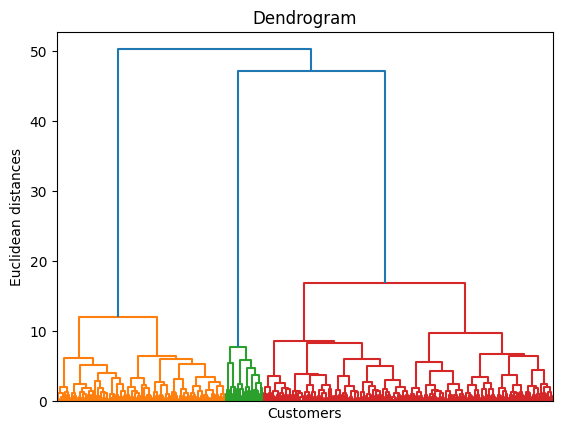

In [5]:
import scipy.cluster.hierarchy as sch

dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'), no_labels=True)
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

Untuk memperkuat pilihan jumlah cluster, dibandingkan nilai silhouette score dan Davies-Bouldin Index (DBI) untuk beberapa jumlah cluster.

In [6]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

for k in range(2, 8):
    labels_k = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    print(f'k = {k} -> silhouette: {silhouette_score(X_scaled, labels_k):.4f} | DBI: {davies_bouldin_score(X_scaled, labels_k):.4f}')

k = 2 -> silhouette: 0.4177 | DBI: 0.9326
k = 3 -> silhouette: 0.5148 | DBI: 0.6810
k = 4 -> silhouette: 0.3481 | DBI: 1.1493
k = 5 -> silhouette: 0.2569 | DBI: 1.3851
k = 6 -> silhouette: 0.2268 | DBI: 1.4109
k = 7 -> silhouette: 0.2163 | DBI: 1.4394


In [7]:
# Model Agglomerative Clustering dengan 3 cluster
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = hc.fit_predict(X_scaled)

df['Cluster'] = labels
print(df['Cluster'].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


In [8]:
# Profil setiap cluster (rata-rata tiap variabel)
df.drop(columns=['Sl_No', 'Customer Key']).groupby('Cluster').mean().round(1)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.9,5.5,3.5,1.0,2.0
1,12151.1,2.4,0.9,3.5,6.9
2,141040.0,8.7,0.6,10.9,1.1


**Jawaban:** Model Agglomerative Clustering (linkage `ward`, jarak euclidean) dibuat dengan **5 variabel** (`Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, `Total_calls_made`) yang sudah distandardisasi. Jumlah cluster yang dipilih adalah **3**, karena nilai silhouette score tertinggi (0.5148) dan DBI terendah (0.6810) terjadi pada k = 3.

Karakteristik tiap cluster:
- **Cluster 0** (385 pelanggan): limit kredit menengah (rata-rata sekitar 33.852), memiliki sekitar 5-6 kartu, paling sering datang langsung ke bank.
- **Cluster 1** (225 pelanggan): limit kredit rendah (rata-rata sekitar 12.151) dengan sekitar 2 kartu, paling sering menghubungi bank lewat telepon.
- **Cluster 2** (50 pelanggan): limit kredit sangat tinggi (rata-rata sekitar 141.040) dengan sekitar 9 kartu, paling sering mengakses layanan secara online dan jarang datang ke bank maupun menelepon.

## Soal 2

Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Tunjukkan bentuk *cluster*-nya berdasarkan dua fitur tersebut.

### Jawaban

Catatan: pada dataset ini nama kolomnya adalah `Total_Credit_Cards` (huruf C kapital dan berakhiran s).

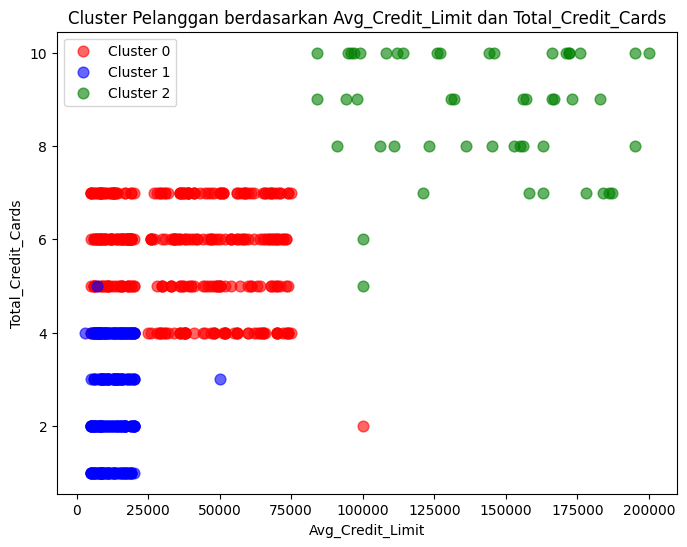

In [9]:
warna = ['red', 'blue', 'green']

plt.figure(figsize=(8, 6))
for k in range(3):
    plt.scatter(df.loc[df['Cluster'] == k, 'Avg_Credit_Limit'],
                df.loc[df['Cluster'] == k, 'Total_Credit_Cards'],
                s=60, c=warna[k], alpha=0.6, label=f'Cluster {k}')
plt.title('Cluster Pelanggan berdasarkan Avg_Credit_Limit dan Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

**Jawaban:** Pada scatterplot terlihat bahwa:
- **Cluster 2** (hijau) berada di kanan atas dan terpisah jelas dari cluster lain, yaitu pelanggan dengan limit kredit sangat tinggi dan jumlah kartu banyak.
- **Cluster 1** (biru) berada di kiri bawah, yaitu limit kredit rendah dengan jumlah kartu sedikit.
- **Cluster 0** (merah) berada di bagian tengah dengan limit menengah dan jumlah kartu menengah. Pada tampilan dua fitur ini, Cluster 0 dan Cluster 1 sedikit saling tumpang tindih karena pemisahan kedua cluster tersebut juga ditentukan oleh variabel lain (kunjungan ke bank, kunjungan online, dan jumlah telepon) yang tidak tampak pada grafik dua dimensi ini.

## Soal 3

Tentukan nilai *silhouette score* dan DBI dari model.

### Jawaban

In [10]:
sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print(f'Silhouette Score     : {sil_score}')
print(f'Davies-Bouldin Index : {dbi_score}')

Silhouette Score     : 0.5147639589977819
Davies-Bouldin Index : 0.680959518994733


**Jawaban:** Model Agglomerative Clustering dengan 3 cluster menghasilkan **silhouette score sebesar 0.5148** dan **Davies-Bouldin Index (DBI) sebesar 0.6810**.

- Silhouette score 0.51 (di atas 0.5) menunjukkan struktur cluster yang cukup baik, dengan cluster yang terpisah wajar satu sama lain.
- DBI 0.68 tergolong rendah (semakin mendekati 0 semakin baik), yang berarti cluster cukup padat dan terpisah dengan jelas.